In [1]:
!pip install pandas

In [2]:
!pip install matplotlib

In [3]:
import pandas as pd
import kagglehub
import glob
import os

# 1. Download the full dataset folder
dataset_path = kagglehub.dataset_download("aamir28/student-sleep-screen-time-and-academic-performance")

# 2. Automatically find any CSV file inside that folder
csv_files = glob.glob(os.path.join(dataset_path, "*.csv"))

if csv_files:
    # 3. Load the first CSV file found
    df = pd.read_csv(csv_files[0])
    print("Successfully loaded:", os.path.basename(csv_files[0]))
    print(df.head())
else:
    print("No CSV files found in the dataset folder.")

100%|██████████| 15.8k/15.8k [00:00<00:00, 16.1MB/s]

Extracting files...
Successfully loaded: student_sleep_screen_time_academic_performance.csv
  student_id  age  gender  year_of_study   major_category  \
0    STU2001   21    Male              3       Humanities   
1    STU2002   20  Female              2             STEM   
2    STU2003   20    Male              4  Social Sciences   
3    STU2004   22       F              1       Humanities   
4    STU2005   23  Female              4  Social Sciences   

         residence_type    chronotype  avg_bedtime_hour  \
0           With Family    Early Bird              22.3   
1             Dormitory  Intermediate              23.1   
2           With Family  Intermediate              23.4   
3  Off-campus Apartment     Night Owl               0.9   
4  Off-campus Apartment    Early Bird              23.4   

   avg_sleep_hours_weekday  weekend_sleep_delta_hours  ...  naps_per_week  \
0                      7.6                        2.0  ...              0   
1                      5.9      

In [4]:
!pip install -q kagglehub

import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download(
    "aamir28/student-sleep-screen-time-and-academic-performance"
)

print("Downloaded files:", os.listdir(path))

Using Colab cache for faster access to the 'student-sleep-screen-time-and-academic-performance' dataset.
Downloaded files: ['.nfs000000007543d4cf000000c6', 'student_sleep_screen_time_academic_performance.csv']


In [5]:
df = pd.read_csv(csv_files[0])

display(df.head())
print(df.shape)

,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74


(500, 25)


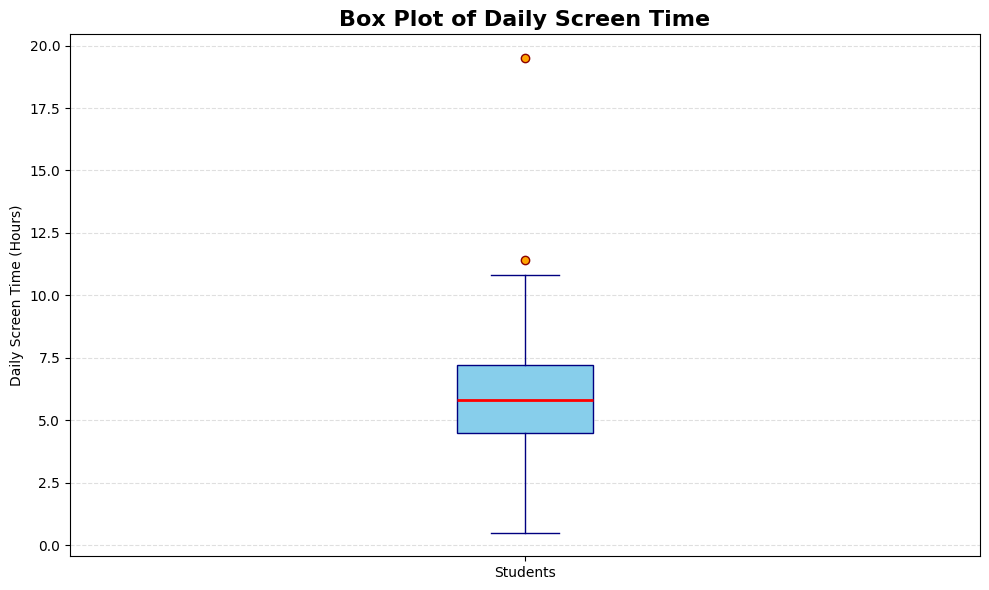

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Load your dataset
df = pd.read_csv(csv_files[0])

# Convert screen time to numeric and remove missing values
screen_time = pd.to_numeric(
    df["daily_screen_time_hours"], errors="coerce"
).dropna()

# Create the box plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    screen_time,
    patch_artist=True,
    boxprops=dict(facecolor="skyblue", color="navy"),
    medianprops=dict(color="red", linewidth=2),
    whiskerprops=dict(color="navy"),
    capprops=dict(color="navy"),
    flierprops=dict(
        marker="o",
        markerfacecolor="orange",
        markeredgecolor="darkred",
        markersize=6
    )
)

ax.set_title("Box Plot of Daily Screen Time", fontsize=16, fontweight="bold")
ax.set_ylabel("Daily Screen Time (Hours)")
ax.set_xticks([1])
ax.set_xticklabels(["Students"])
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save and display the image
filename = "/content/Daily_Screen_Time_Boxplot.png"
fig.savefig(filename, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# Download the image
files.download(filename)


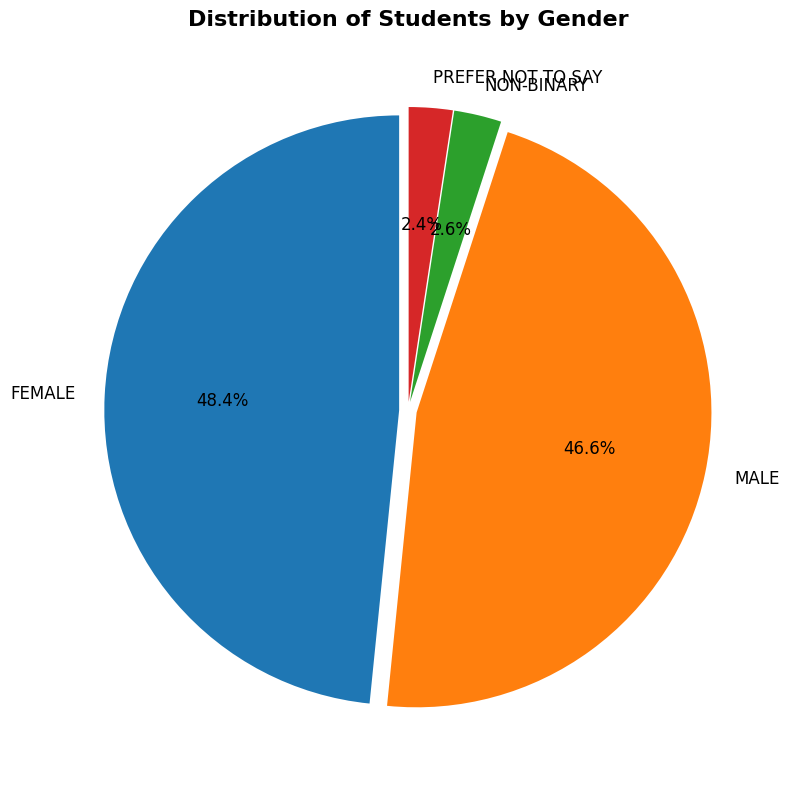

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Load your dataset
df = pd.read_csv(csv_files[0])

# Clean gender categories
gender = (
    df["gender"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "M": "MALE",
        "F": "FEMALE"
    })
)

# Count students in each gender category
gender_counts = gender.dropna().value_counts()

# Create pie chart
fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.03] * len(gender_counts),
    shadow=False,
    textprops={"fontsize": 12}
)

ax.set_title(
    "Distribution of Students by Gender",
    fontsize=16,
    fontweight="bold"
)
ax.axis("equal")

plt.tight_layout()

# Save the image
filename = "/content/Student_Gender_Pie_Chart.png"
fig.savefig(filename, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# Download the chart
files.download(filename)


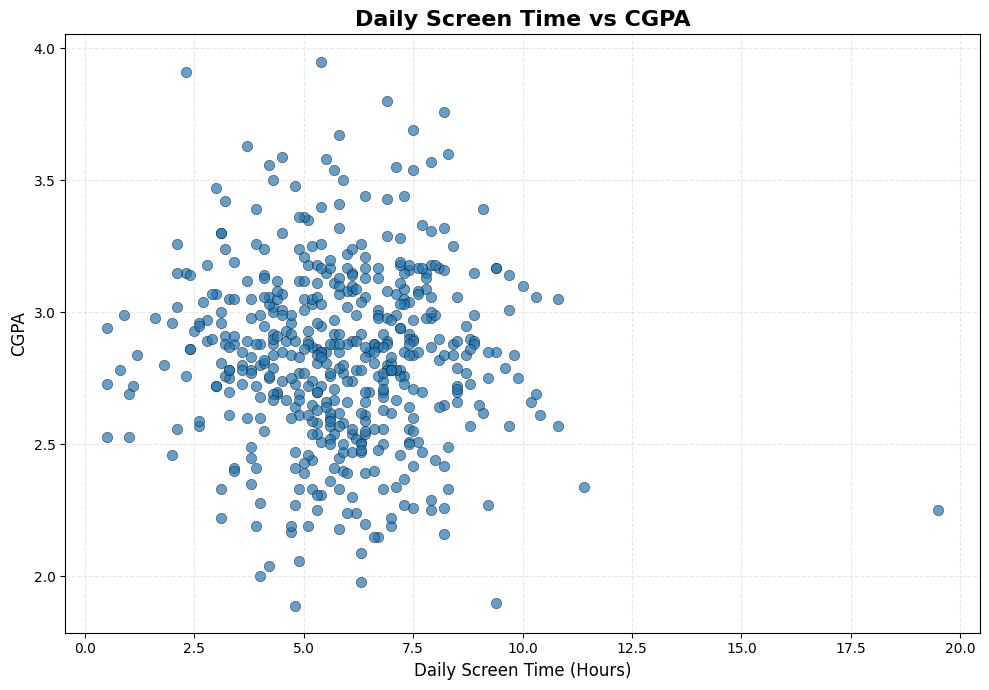

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Load your dataset
df = pd.read_csv(csv_files[0])

# Select columns and remove missing or non-numeric values
data = df[["daily_screen_time_hours", "cgpa"]].copy()

data["daily_screen_time_hours"] = pd.to_numeric(
    data["daily_screen_time_hours"], errors="coerce"
)
data["cgpa"] = pd.to_numeric(data["cgpa"], errors="coerce")
data = data.dropna()

# Create scatter plot
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    data["daily_screen_time_hours"],
    data["cgpa"],
    alpha=0.7,
    s=55,
    edgecolors="black",
    linewidths=0.4
)

ax.set_title(
    "Daily Screen Time vs CGPA",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Daily Screen Time (Hours)", fontsize=12)
ax.set_ylabel("CGPA", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()

# Save the chart
filename = "/content/Screen_Time_vs_CGPA_Scatter_Plot.png"
fig.savefig(filename, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# Download the chart
files.download(filename)


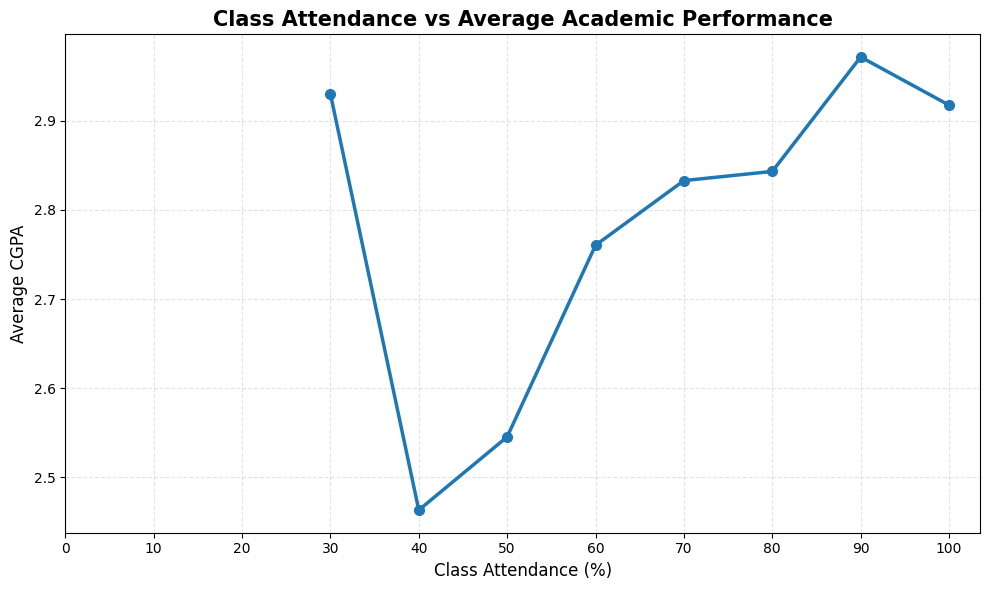

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Load your dataset
df = pd.read_csv(csv_files[0])

# Convert columns to numeric
df["class_attendance_percent"] = pd.to_numeric(
    df["class_attendance_percent"], errors="coerce"
)
df["cgpa"] = pd.to_numeric(df["cgpa"], errors="coerce")

# Keep rows with valid attendance and CGPA
data = df[
    ["class_attendance_percent", "cgpa"]
].dropna().copy()

# Group attendance into 10-percentage-point intervals
data["attendance_group"] = (
    (data["class_attendance_percent"] // 10) * 10
).clip(0, 100)

# Calculate average CGPA for each attendance group
summary = (
    data.groupby("attendance_group")["cgpa"]
    .mean()
    .sort_index()
)

# Create the line chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    summary.index,
    summary.values,
    marker="o",
    linewidth=2.5,
    markersize=7
)

ax.set_title(
    "Class Attendance vs Average Academic Performance",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Class Attendance (%)", fontsize=12)
ax.set_ylabel("Average CGPA", fontsize=12)
ax.set_xticks(range(0, 101, 10))
ax.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()

# Save the chart
filename = "/content/Attendance_vs_Academic_Performance.png"
fig.savefig(filename, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# Download the chart
files.download(filename)


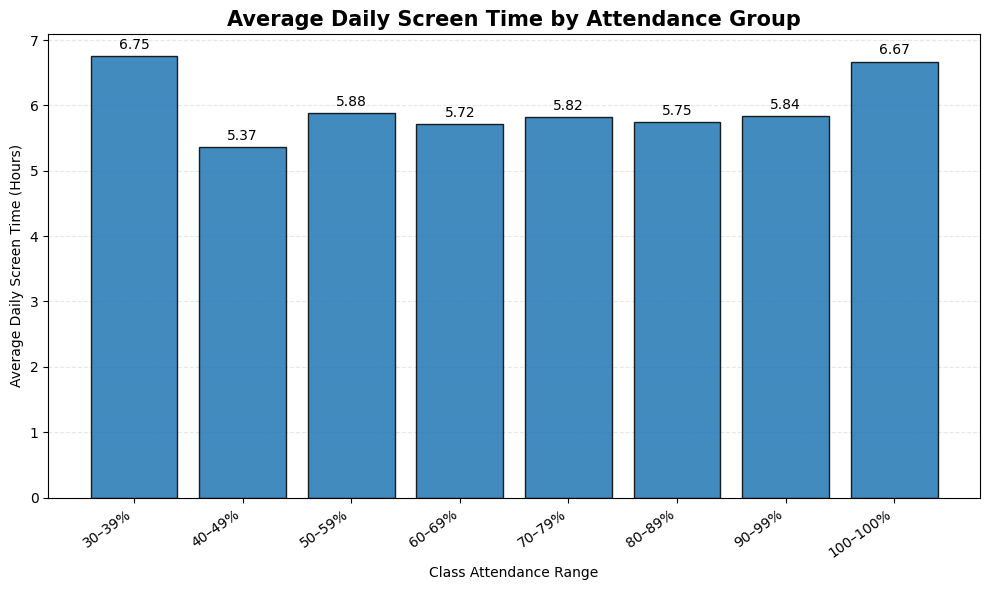

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

# Load your dataset
df = pd.read_csv(csv_files[0])

# Convert columns to numeric
df["class_attendance_percent"] = pd.to_numeric(
    df["class_attendance_percent"], errors="coerce"
)
df["daily_screen_time_hours"] = pd.to_numeric(
    df["daily_screen_time_hours"], errors="coerce"
)

# Remove missing values
data = df[
    ["class_attendance_percent", "daily_screen_time_hours"]
].dropna().copy()

# Group attendance into 10-percentage-point intervals
data["attendance_group"] = (
    (data["class_attendance_percent"] // 10) * 10
).clip(0, 100)

# Calculate average screen time for each group
summary = (
    data.groupby("attendance_group")["daily_screen_time_hours"]
    .mean()
    .sort_index()
)

# Create attendance labels safely using NumPy
starts = summary.index.to_numpy(dtype=int)
ends = np.minimum(starts + 9, 100)
labels = [f"{start}–{end}%" for start, end in zip(starts, ends)]

# Create bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    labels,
    summary.values,
    edgecolor="black",
    alpha=0.85
)

ax.bar_label(bars, fmt="%.2f", padding=3)

ax.set_title(
    "Average Daily Screen Time by Attendance Group",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Class Attendance Range")
ax.set_ylabel("Average Daily Screen Time (Hours)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

# Save, display, and download the chart
filename = "/content/Attendance_vs_Screen_Time_Bar_Chart.png"
fig.savefig(filename, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

files.download(filename)
